In [2]:
import numpy as np

# Example data
study_hours = np.array([1,2,3,4,5])
marks = np.array([40,50,60,70,80])

# Variance of X
variance_x = np.var(study_hours)

# Covariance of X and Y
covariance_xy = np.cov(study_hours, marks)[0,1]

# OLS slope
beta_1 = covariance_xy / variance_x

print("Variance of X:", variance_x)
print("Covariance of X and Y:", covariance_xy)
print("OLS slope:", beta_1)

Variance of X: 2.0
Covariance of X and Y: 25.0
OLS slope: 12.5


In [3]:
np.cov(study_hours, marks)[1,1]



np.float64(250.0)

In [1]:
from statsmodels.tsa.arima.model import ARIMA 
model=ARIMA(y,order=(1,1,1))
model_fit = model.fit()
print(model_fit.summary())

NameError: name 'y' is not defined

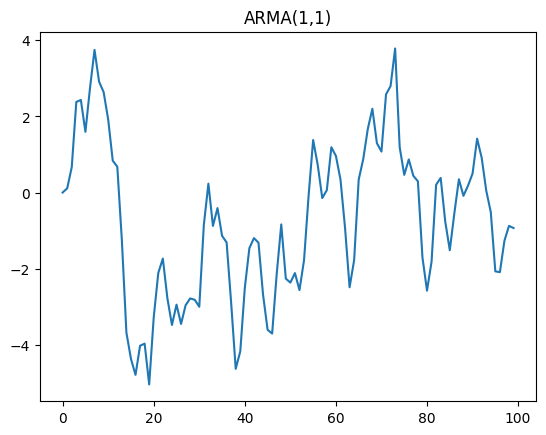

In [2]:
import numpy as np
import matplotlib.pyplot as plt

# fix randomness
np.random.seed(42)

# number of observations
n = 100

# white noise
errors = np.random.normal(0,1,n)

# empty series
y = np.zeros(n)

# coefficients
phi = 0.8
theta = 0.5

# generate ARMA(1,1)
for t in range(1,n):
    y[t] = phi*y[t-1] + errors[t] + theta*errors[t-1]

# plot
plt.plot(y)
plt.title("ARMA(1,1)")
plt.show()

In [3]:
from statsmodels.tsa.arima.model import ARIMA

model = ARIMA(y, order=(1,1,1))

model_fit = model.fit()

print(model_fit.summary())

                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                  100
Model:                 ARIMA(1, 1, 1)   Log Likelihood                -134.568
Date:                Wed, 10 Jun 2026   AIC                            275.135
Time:                        14:15:07   BIC                            282.921
Sample:                             0   HQIC                           278.285
                                - 100                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.4517      0.170     -2.662      0.008      -0.784      -0.119
ma.L1          0.8351      0.097      8.614      0.000       0.645       1.025
sigma2         0.8832      0.118      7.504      0.0

In [4]:
model = ARIMA(y, order=(1,0,1))
model_fit = model.fit()
print(model_fit.summary())

                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                  100
Model:                 ARIMA(1, 0, 1)   Log Likelihood                -132.489
Date:                Wed, 10 Jun 2026   AIC                            272.979
Time:                        14:43:59   BIC                            283.399
Sample:                             0   HQIC                           277.196
                                - 100                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         -0.7467      0.590     -1.266      0.206      -1.903       0.409
ar.L1          0.7648      0.071     10.843      0.000       0.627       0.903
ma.L1          0.5256      0.104      5.066      0.0

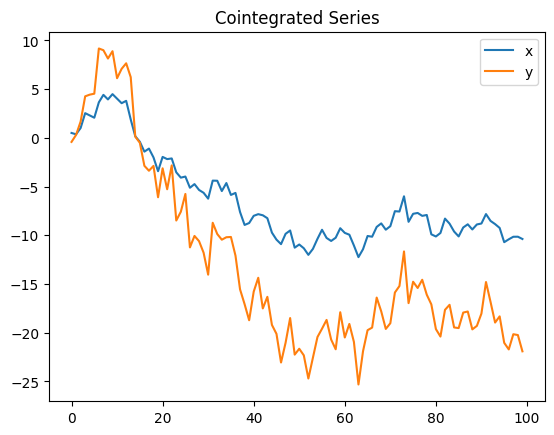

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import adfuller
import statsmodels.api as sm

np.random.seed(42)

n = 100

# random walk
x = np.cumsum(np.random.normal(0,1,n))

# y tied to x (cointegrated)
y = 2*x + np.random.normal(0,1,n)

# plot
plt.plot(x, label="x")
plt.plot(y, label="y")
plt.legend()
plt.title("Cointegrated Series")
plt.show()

In [1]:
print("ADF for x:", adfuller(x)[1])
print("ADF for y:", adfuller(y)[1])

NameError: name 'adfuller' is not defined

In [2]:
from statsmodels.tsa.stattools import adfuller

In [3]:
print("ADF for x:", adfuller(x)[1])
print("ADF for y:", adfuller(y)[1])

NameError: name 'x' is not defined

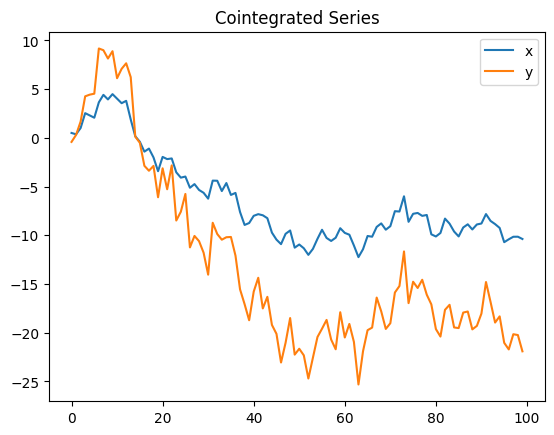

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import adfuller
import statsmodels.api as sm

np.random.seed(42)

n = 100

# random walk
x = np.cumsum(np.random.normal(0,1,n))

# y tied to x (cointegrated)
y = 2*x + np.random.normal(0,1,n)

# plot
plt.plot(x, label="x")
plt.plot(y, label="y")
plt.legend()
plt.title("Cointegrated Series")
plt.show()

In [5]:
print("ADF for x:", adfuller(x)[1])
print("ADF for y:", adfuller(y)[1])

ADF for x: 0.6020814791099101
ADF for y: 0.6414992780915709


In [9]:
# regression
X = sm.add_constant(x)
model = sm.OLS(y, X).fit()

# residuals
residuals = model.resid

# ADF on residuals
print("Residual p-value:", adfuller(residuals)[1])

Residual p-value: 1.3577542960215078e-19


In [12]:
import numpy as np
import pandas as pd 
from statsmodels.tsa.api import  VAR 
np.random.seed(42)
n = 100 
#create gdp 
gdp = np.cumsum(np.random.normal(0,1,n))
#inflation partly depends on gdp 
inflation = 0.5*np.roll(gdp,1)+np.random.normal(0,1,n)
#data frames 
data =pd.DataFrame({
    'GDP':gdp,
    'Inflation': inflation 
})
#fit var 
model = VAR(data)
results = model.fit(1)
print(results.summary())

  Summary of Regression Results   
Model:                         VAR
Method:                        OLS
Date:           Fri, 12, Jun, 2026
Time:                     15:19:42
--------------------------------------------------------------------
No. of Equations:         2.00000    BIC:                 -0.0870812
Nobs:                     99.0000    HQIC:                 -0.180725
Log likelihood:          -262.854    FPE:                   0.783234
AIC:                    -0.244361    Det(Omega_mle):        0.737839
--------------------------------------------------------------------
Results for equation GDP
                  coefficient       std. error           t-stat            prob
-------------------------------------------------------------------------------
const               -0.290574         0.155281           -1.871           0.061
L1.GDP               1.007803         0.038804           25.971           0.000
L1.Inflation        -0.073128         0.070747           -1.034   

In [15]:
from statsmodels.tsa.stattools import grangercausalitytests 
granger_test = grangercausalitytests(
    data [['Inflation','GDP']],
    maxlag = 1 
)


Granger Causality
number of lags (no zero) 1
ssr based F test:         F=163.3629, p=0.0000  , df_denom=96, df_num=1
ssr based chi2 test:   chi2=168.4679, p=0.0000  , df=1
likelihood ratio test: chi2=98.3941 , p=0.0000  , df=1
parameter F test:         F=163.3629, p=0.0000  , df_denom=96, df_num=1


In [16]:
# Forecast next 5 periods

forecast = results.forecast(
    data.values[-1:], 
    steps=5
)

forecast_df = pd.DataFrame(
    forecast,
    columns=['GDP_forecast','Inflation_forecast']
)

print(forecast_df)

   GDP_forecast  Inflation_forecast
0    -10.301542           -5.151996
1    -10.295739           -5.141583
2    -10.290652           -5.138871
3    -10.285723           -5.136296
4    -10.280945           -5.133799


In [20]:
#chossing optimal lag 
lag_order = model.select_order(maxlags = 5 )
print (lag_order.summary())

 VAR Order Selection (* highlights the minimums) 
      AIC         BIC         FPE         HQIC   
-------------------------------------------------
0       3.186       3.239       24.18       3.207
1    -0.2358*   -0.07451*     0.7900*    -0.1706*
2     -0.1777     0.09117      0.8374    -0.06903
3     -0.1171      0.2592      0.8900     0.03496
4     -0.1022      0.3817      0.9038     0.09330
5    -0.03121      0.5602      0.9713      0.2078
-------------------------------------------------


In [21]:
import numpy as np
import pandas as pd
import statsmodels.api as sm

np.random.seed(42)

n = 100

# create cointegrated variables
x = np.cumsum(np.random.normal(0,1,n))
y = 2*x + np.random.normal(0,1,n)

# long-run regression
X = sm.add_constant(x)
long_run = sm.OLS(y, X).fit()

# residuals (error correction term)
ecm = long_run.resid

# first differences
dy = np.diff(y)
dx = np.diff(x)

# lagged ECM term
ecm_lag = ecm[:-1]

# make same length
data = pd.DataFrame({
    'dy': dy,
    'dx': dx,
    'ecm_lag': ecm_lag
})

# ECM regression
X_ecm = sm.add_constant(data[['dx','ecm_lag']])
ecm_model = sm.OLS(data['dy'], X_ecm).fit()

print(ecm_model.summary())

                            OLS Regression Results                            
Dep. Variable:                     dy   R-squared:                       0.836
Model:                            OLS   Adj. R-squared:                  0.833
Method:                 Least Squares   F-statistic:                     244.9
Date:                Sun, 14 Jun 2026   Prob (F-statistic):           1.98e-38
Time:                        14:46:13   Log-Likelihood:                -133.17
No. Observations:                  99   AIC:                             272.3
Df Residuals:                      96   BIC:                             280.1
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         -0.0006      0.095     -0.006      0.9